# Results: Laya, `laya-ft` and Jev on the evaluation split

The full runs are done: Laya and Jev answered all 100,000 products of the sample, `laya-ft` the 90,000 of the evaluation split.
This notebook turns their answers into the numbers the README reports.

1. **The runs**: which version answered, where, and what was cut or failed.
2. **Accuracy** per question, against the baselines and the predictions written before the runs.
3. **Names seen in training**: whether `laya-ft` learned the task or the products.
4. **Where the answers go**: what each system answers instead of the right label.
5. **Agreement**: how often `laya-ft` and Jev answer the same, and ten products where they do not.
6. **Confidence**: Laya's temperature fitted on the calibration split, and how far each system's confidence can be trusted.
7. **Accuracy against coverage**: the accuracy on the products each system is surest about.
8. **Speed and cost**.

Every number comes from the 90,000 products of the evaluation split.
The calibration split is used once, in section 6, to fit Laya's temperature.
The Jev numbers stay inside Xebia until TypeSafe's terms on publishing benchmarks have been read.

The notebook reads `data/runs/full/results.parquet`, written by `just build`, and sends no request.

In [1]:
import json
import os
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# The notebooks live in notebooks/; every path below is from the project root
os.chdir(next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists()))

assert Path(sys.prefix).resolve() == Path(".venv").resolve(), (
    f"The kernel runs {sys.executable}, not this project's .venv. Start Jupyter with `just lab`."
)

from laya.calibrate import fit_temperature_map
from laya.common import QTYPES, ece_score, temp_bucket

from harness.questions import OPTIONS, QUESTIONS, truth_of
from harness.runs import RUNS, SAMPLE

RUN = RUNS / "full"
FIGURES = Path("notebooks/figures")
SYSTEMS = ["laya", "laya-ft", "jev"]
NAMES = {"laya": "Laya", "laya-ft": "laya-ft", "jev": "Jev"}
COUNT = {0: "none", 1: "one", 2: "two", 3: "all three"}

con = duckdb.connect()

In [2]:
def sql(query: str) -> pd.DataFrame:
    return con.sql(query).df()


def show(df: pd.DataFrame, precision: int = 2) -> None:
    display(df.style.hide(axis="index").format(thousands=",", precision=precision, escape="html"))


def pct(value: float, digits: int = 1) -> str:
    return f"{value:.{digits}%}"


INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
GRAY = "#b5b3aa"
COLOR = {"laya": "#2a78d6", "laya-ft": "#1baf7a", "jev": "#eb6834"}  # the first three categorical slots, in order
SHADES = LinearSegmentedColormap.from_list("shares", [SURFACE, "#2c2c2a"])  # one hue, light to dark

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "figure.dpi": 120,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10.5,
    "text.color": INK,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titlesize": 10.5,
    "axes.titlecolor": INK_2,
    "axes.titlepad": 10,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": MUTED,
    "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})


def percent_axis(ax, axis: str = "x") -> None:
    getattr(ax, f"{axis}axis").set_major_formatter(lambda value, _: f"{value:.0%}")


def headline(fig, text: str) -> None:
    fig.suptitle(text, x=0.01, ha="left", fontweight="bold", fontsize=12)

In [3]:
sample = sql(f"SELECT id, split, name, food_group, ultra_processed, nutriscore FROM read_parquet('{SAMPLE}')")
truth = {row.id: truth_of(row.food_group, row.ultra_processed, row.nutriscore) for row in sample.itertuples()}
name_of = dict(zip(sample.id, sample.name))

results = sql(f"FROM read_parquet('{RUN / 'results.parquet'}')")
results["truth"] = [truth[id][question] for id, question in zip(results.id, results.question)]
results["right"] = (results.answer == results.truth).fillna(False).astype(bool)  # never answered counts as wrong
results["confidence"] = [probs[answer] if probs is not None else np.nan
                         for probs, answer in zip(results.probs, results.answer)]
evaluation = results[results.split == "evaluation"]
print(f"{len(results):,} answers, {len(evaluation):,} of them on the {evaluation.id.nunique():,} evaluation products")

870,000 answers, 810,000 of them on the 90,000 evaluation products


## 1. The runs

Each system answered in one run, pinned to one version, through the same harness and the same questions.

In [4]:
WHERE = {"cuda": "DGX Spark (CUDA)", "mps": "M3 Pro laptop (MPS)"}

rows = []
for system in SYSTEMS:
    manifest = json.loads((RUN / f"{system}.json").read_text())
    devices = sorted({invocation["health"]["device"] for invocation in manifest["invocations"] if invocation["health"]})
    answers = evaluation[evaluation.system == system]
    products = answers.drop_duplicates("id")
    rows.append({
        "system": NAMES[system],
        "version": manifest["pinned"]["model_version"],
        "answered on": ", ".join(WHERE[device] for device in devices) or "TypeSafe's API",
        "evaluation products": len(products),
        "never answered": int(products.error.notna().sum()),
        "needed a retry": int((products.attempts > 1).sum()),
        "rows with a cut state": (f"{int(answers.truncated.sum()):,} of {len(answers):,}"
                                  if answers.truncated.notna().any() else "not reported"),
    })
show(pd.DataFrame(rows))

system,version,answered on,evaluation products,never answered,needed a retry,rows with a cut state
Laya,"laya 0.4.18, english@7b928d8",DGX Spark (CUDA),"90,000",0,0,"4,038 of 270,000"
laya-ft,"laya 0.4.18, laya-ft@c4b23c4",DGX Spark (CUDA),"90,000",0,0,"4,038 of 270,000"
Jev,jev-1.14.0,TypeSafe's API,"90,000",0,23,not reported


- No product failed for good, so every accuracy below is over all 90,000 products.
- Laya and `laya-ft` cut the same rows: they share the tokenizer, the questions and the limit of 512 tokens.
- Jev reports no truncation, and its limits are not published.

## 2. Accuracy

The share of right answers per question, against two simple strategies: guessing at random, and always giving the most common answer of the evaluation split, the majority baseline.

In [5]:
evaluation_truth = pd.DataFrame([truth[id] for id in sample.id[sample.split == "evaluation"]])
baseline = {question: evaluation_truth[question].value_counts(normalize=True).max() for question in QUESTIONS}
accuracy = (evaluation.pivot_table(index="question", columns="system", values="right", aggfunc="mean")
            .reindex(index=list(QUESTIONS), columns=SYSTEMS))

show(pd.DataFrame({
    "question": list(QUESTIONS),
    "random guess": [pct(1 / len(OPTIONS[question]), 0) for question in QUESTIONS],
    "majority baseline": [pct(baseline[question]) for question in QUESTIONS],
    **{NAMES[system]: [pct(accuracy.loc[question, system]) for question in QUESTIONS] for system in SYSTEMS},
}))

question,random guess,majority baseline,Laya,laya-ft,Jev
food_group,10%,23.3%,52.9%,89.2%,86.9%
ultra_processed,50%,67.0%,62.6%,97.6%,89.8%
nutriscore,20%,30.8%,11.4%,81.5%,51.8%


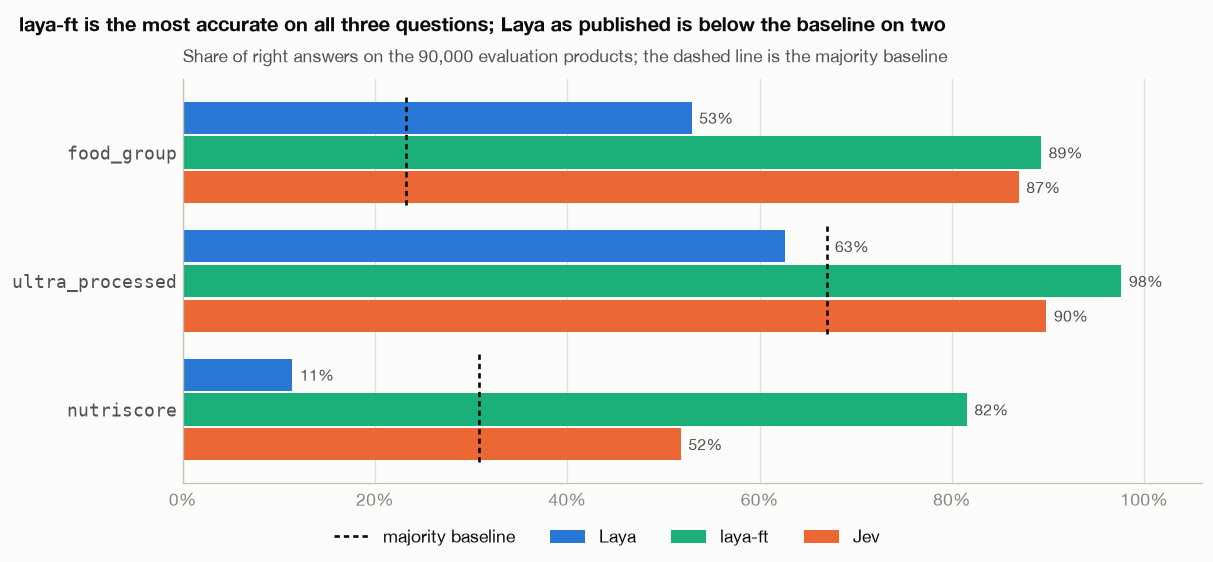

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
offsets = dict(zip(SYSTEMS, (-0.27, 0, 0.27)))
for row, question in enumerate(QUESTIONS):
    for system in SYSTEMS:
        value = accuracy.loc[question, system]
        ax.barh(row + offsets[system], value, height=0.25, color=COLOR[system], label=NAMES[system] if row == 0 else None)
        x = value + 0.008
        if value < baseline[question] < x + 0.045:  # step over the baseline rather than write across it
            x = baseline[question] + 0.008
        ax.text(x, row + offsets[system], pct(value, 0), va="center", color=INK_2, fontsize=9.5)
    ax.plot([baseline[question]] * 2, [row - 0.43, row + 0.43], color=INK, linewidth=1.6, linestyle=(0, (2, 1.5)),
            label="majority baseline" if row == 0 else None)
ax.set_yticks(range(len(QUESTIONS)), list(QUESTIONS), fontfamily="monospace")
ax.invert_yaxis()
ax.set_xlim(0, 1.06)
percent_axis(ax)
ax.tick_params(length=0)
ax.grid(axis="y", visible=False)
fig.legend(loc="outside lower center", ncols=4)

leaders = {accuracy.loc[question].idxmax() for question in QUESTIONS}
below = [question for question in QUESTIONS if accuracy.loc[question, "laya"] < baseline[question]]
leader = (f"{NAMES[leaders.pop()]} is the most accurate on all three questions" if len(leaders) == 1
          else "No system is the most accurate on every question")
headline(fig, f"{leader}; Laya as published is below the baseline on {COUNT[len(below)]}")
ax.set_title("Share of right answers on the 90,000 evaluation products; the dashed line is the majority baseline")
plt.show()

### `nutriscore`: how far off

Only the exact grade counts as right, but the grades are ordered: B for a C is a smaller mistake than E for an A.

In [7]:
GRADES = OPTIONS["nutriscore"]
nutriscore = evaluation[evaluation.question == "nutriscore"]

rows = []
for system in SYSTEMS:
    answers = nutriscore[nutriscore.system == system]
    off = (answers.answer.map(GRADES.index) - answers.truth.map(GRADES.index)).abs()
    common = answers.answer.value_counts(normalize=True)
    rows.append({
        "system": NAMES[system],
        "exact grade": pct((off == 0).mean()),
        "within one grade": pct((off <= 1).mean()),
        "grades off, on average": f"{off.mean():.2f}",
        "most common answer": f"{common.index[0]}, for {pct(common.iloc[0], 0)} of the products",
    })
labels = evaluation_truth.nutriscore.value_counts(normalize=True)
rows.append({"system": "the labels", "most common answer": f"{labels.index[0]}, for {pct(labels.iloc[0], 0)} of the products"})
show(pd.DataFrame(rows).fillna(""))

system,exact grade,within one grade,"grades off, on average",most common answer
Laya,11.4%,47.3%,1.70,"B, for 91% of the products"
laya-ft,81.5%,98.3%,0.20,"E, for 29% of the products"
Jev,51.8%,92.2%,0.57,"D, for 35% of the products"
the labels,,,,"E, for 31% of the products"


### Products whose state Laya cuts

Laya reads at most 512 tokens, so on the longest states it never sees the end of the ingredients.
Jev reads them whole; its accuracy on the same products shows how hard they are anyway.

In [8]:
cut = evaluation[evaluation.system == "laya"].set_index(["id", "question"]).truncated.astype(bool).rename("cut")
marked = evaluation.join(cut, on=["id", "question"])
right_by_cut = marked.groupby(["question", "cut", "system"]).right.mean()
products_by_cut = marked[marked.system == "jev"].groupby(["question", "cut"]).size()

show(pd.DataFrame([
    {
        "question": question,
        "state": "cut" if is_cut else "whole",
        "products": products_by_cut[question, is_cut],
        **{NAMES[system]: pct(right_by_cut[question, is_cut, system]) for system in SYSTEMS},
    }
    for question in QUESTIONS for is_cut in (False, True)
]))

question,state,products,Laya,laya-ft,Jev
food_group,whole,"87,488",52.8%,89.4%,86.9%
food_group,cut,"2,512",57.7%,84.2%,87.2%
ultra_processed,whole,"89,272",62.3%,97.6%,89.7%
ultra_processed,cut,728,98.4%,99.2%,99.5%
nutriscore,whole,"89,202",11.4%,81.7%,51.7%
nutriscore,cut,798,12.9%,56.6%,61.2%


In [9]:
whole, cut_short = right_by_cut["nutriscore", False, "laya-ft"], right_by_cut["nutriscore", True, "laya-ft"]
display(Markdown("\n".join([
    (f"- The nutrition line comes last in every state, so it is the first thing a cut removes: on `nutriscore`, "
     f"`laya-ft` falls from {pct(whole)} on whole states to {pct(cut_short)} on cut ones, "
     f"where Jev, which reads them whole, gets {pct(right_by_cut['nutriscore', True, 'jev'])}."),
    (f"- On `ultra_processed` the cut states are easy for every system: they are the longest ingredient lists, "
     f"and Jev is right on {pct(right_by_cut['ultra_processed', True, 'jev'])} of them."),
])))

- The nutrition line comes last in every state, so it is the first thing a cut removes: on `nutriscore`, `laya-ft` falls from 81.7% on whole states to 56.6% on cut ones, where Jev, which reads them whole, gets 61.2%.
- On `ultra_processed` the cut states are easy for every system: they are the longest ingredient lists, and Jev is right on 99.5% of them.

### Predictions against results

The predictions table of the README was filled in before the first request, and its `laya-ft` column before the training run.

In [10]:
# The README's predictions table, written before the runs
PREDICTIONS = {
    "food_group": {"baseline": 0.22, "laya": 0.60, "jev": 0.70, "laya-ft": 0.72},
    "ultra_processed": {"baseline": 0.70, "laya": 0.65, "jev": 0.80, "laya-ft": 0.82},
    "nutriscore": {"baseline": 0.28, "laya": 0.25, "jev": 0.35, "laya-ft": 0.40},
}

rows = []
for question, guesses in PREDICTIONS.items():
    for what, guess in guesses.items():
        measured = baseline[question] if what == "baseline" else accuracy.loc[question, what]
        rows.append({
            "question": question,
            "of": "majority baseline" if what == "baseline" else NAMES[what],
            "predicted": pct(guess, 0),
            "measured": pct(measured),
            "off by": f"{(measured - guess) * 100:+.1f} points",
            "miss": abs(measured - guess),
        })
misses = pd.DataFrame(rows)
show(misses.drop(columns="miss"))

question,of,predicted,measured,off by
food_group,majority baseline,22%,23.3%,+1.3 points
food_group,Laya,60%,52.9%,-7.1 points
food_group,Jev,70%,86.9%,+16.9 points
food_group,laya-ft,72%,89.2%,+17.2 points
ultra_processed,majority baseline,70%,67.0%,-3.0 points
ultra_processed,Laya,65%,62.6%,-2.4 points
ultra_processed,Jev,80%,89.8%,+9.8 points
ultra_processed,laya-ft,82%,97.6%,+15.6 points
nutriscore,majority baseline,28%,30.8%,+2.8 points
nutriscore,Laya,25%,11.4%,-13.6 points


In [11]:
worst = misses.sort_values("miss", ascending=False).head(3)
display(Markdown("The three largest misses:\n\n" + "\n".join(
    f"- {row.of} on `{row.question}`: predicted {row.predicted}, measured {row.measured}." for row in worst.itertuples()
)))

The three largest misses:

- laya-ft on `nutriscore`: predicted 40%, measured 81.5%.
- laya-ft on `food_group`: predicted 72%, measured 89.2%.
- Jev on `food_group`: predicted 70%, measured 86.9%.

## 3. Names seen in training

`laya-ft` was trained on the 10,000 calibration products.
Some evaluation products carry the name of one of them, ignoring case: often the same product in another size, or sold again by another shop.
If `laya-ft` had learned the products rather than the task, it would be far better on those than on the rest.

In [12]:
key = sample.name.str.strip().str.lower()
seen = dict(zip(sample.id, key.isin(set(key[sample.split == "calibration"]))))
named = evaluation.assign(seen=evaluation.id.map(seen))
right_by_name = named.groupby(["question", "seen", "system"]).right.mean()
products_by_name = named[named.system == "jev"].groupby(["question", "seen"]).size()

show(pd.DataFrame([
    {
        "question": question,
        "name": "seen in training" if is_seen else "not seen",
        "products": products_by_name[question, is_seen],
        **{NAMES[system]: pct(right_by_name[question, is_seen, system]) for system in SYSTEMS},
    }
    for question in QUESTIONS for is_seen in (False, True)
]))

question,name,products,Laya,laya-ft,Jev
food_group,not seen,"76,413",51.5%,88.4%,86.3%
food_group,seen in training,"13,587",60.9%,94.2%,90.2%
ultra_processed,not seen,"76,413",62.4%,97.5%,89.8%
ultra_processed,seen in training,"13,587",63.9%,98.2%,89.6%
nutriscore,not seen,"76,413",11.1%,80.8%,51.5%
nutriscore,seen in training,"13,587",12.8%,85.3%,53.2%


In [13]:
unseen, products = products_by_name["food_group", False], evaluation.id.nunique()
ahead_unseen = [question for question in QUESTIONS
                if right_by_name[question, False, "laya-ft"] > right_by_name[question, False, "jev"]]
lines = [(f"- {unseen:,} evaluation products, {pct(unseen / products)}, have a name `laya-ft` never saw; "
          f"on those it is ahead of Jev on {COUNT[len(ahead_unseen)]} questions.")]
beyond = {}
for question in QUESTIONS:
    ft_gain = right_by_name[question, True, "laya-ft"] - right_by_name[question, False, "laya-ft"]
    jev_gain = right_by_name[question, True, "jev"] - right_by_name[question, False, "jev"]
    beyond[question] = ft_gain - jev_gain
    lines.append(f"- `{question}`: a seen name adds {ft_gain * 100:+.1f} points for `laya-ft`, "
                 f"and {jev_gain * 100:+.1f} for Jev, which never trained on any of them.")
most = max(beyond.values())
lines.append(f"- Beyond what Jev gains on the same products, a seen name is worth at most {most * 100:.1f} points to `laya-ft`, "
             f"on {pct(1 - unseen / products)} of the products: at most {most * (1 - unseen / products) * 100:.1f} points "
             "of its overall accuracy come from having seen a product's name.")
display(Markdown("\n".join(lines)))

- 76,413 evaluation products, 84.9%, have a name `laya-ft` never saw; on those it is ahead of Jev on all three questions.
- `food_group`: a seen name adds +5.9 points for `laya-ft`, and +3.8 for Jev, which never trained on any of them.
- `ultra_processed`: a seen name adds +0.8 points for `laya-ft`, and -0.3 for Jev, which never trained on any of them.
- `nutriscore`: a seen name adds +4.5 points for `laya-ft`, and +1.7 for Jev, which never trained on any of them.
- Beyond what Jev gains on the same products, a seen name is worth at most 2.8 points to `laya-ft`, on 15.1% of the products: at most 0.4 points of its overall accuracy come from having seen a product's name.

## 4. Where the answers go

Each row is a true label, with its number of evaluation products, and each cell the share of those products a system put in that column.
The diagonal holds the right answers.
Alcoholic beverages has only 3 evaluation products, too few to score: its row is shown, but nothing is read from it.

In [14]:
SHORT = {
    "alcoholic beverages": "alcohol",
    "beverages": "beverages",
    "cereals and potatoes": "cereals, potatoes",
    "composite foods": "composite",
    "fats and sauces": "fats, sauces",
    "fish, meat and eggs": "fish, meat, eggs",
    "fruits and vegetables": "fruit, vegetables",
    "milk and dairy products": "dairy",
    "salty snacks": "salty snacks",
    "sugary snacks": "sugary snacks",
}


def confusion(system: str, question: str) -> pd.DataFrame:
    answers = evaluation[(evaluation.system == system) & (evaluation.question == question)]
    options = OPTIONS[question]
    return pd.crosstab(answers.truth, answers.answer, normalize="index").reindex(index=options, columns=options,
                                                                                fill_value=0)


MIN_PRODUCTS = 30  # a label with fewer evaluation products is too small to score


def worst_mistake(system: str, question: str) -> tuple[str, str, float]:
    """The true label and wrong answer with the largest share of that label's products, among labels large enough."""
    counts = evaluation_truth[question].value_counts()
    shares = confusion(system, question).stack()
    shares = shares[[label != answer and counts.get(label, 0) >= MIN_PRODUCTS for label, answer in shares.index]]
    (label, answer), share = shares.idxmax(), shares.max()
    return label, answer, share


def confusion_chart(question: str, short: dict, size: tuple[float, float], rotate: bool = True):
    counts = evaluation_truth[question].value_counts()
    fig, axes = plt.subplots(1, 3, figsize=size, layout="constrained", sharey=True)
    for ax, system in zip(axes, SYSTEMS):
        matrix = confusion(system, question)
        ax.imshow(matrix.values, cmap=SHADES, vmin=0, vmax=1)
        for (row, column), share in np.ndenumerate(matrix.values):
            if share >= 0.05 or row == column:  # the diagonal and the larger mistakes only
                ax.text(column, row, f"{share:.0%}", ha="center", va="center", fontsize=8.5,
                        color="white" if share > 0.5 else INK)
        ax.set_xticks(range(len(matrix)), [short[option] for option in matrix.columns], rotation=45 if rotate else 0,
                      ha="right" if rotate else "center", rotation_mode="anchor")
        ax.set_yticks(range(len(matrix)), [
            f"{short[option]}  {counts[option]:,}" + (", too few" if counts[option] < MIN_PRODUCTS else "")
            for option in matrix.index
        ])
        ax.set_title(NAMES[system], color=INK, fontweight="bold")
        ax.set_xlabel("answered")
        ax.grid(False)
        ax.tick_params(length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
    axes[0].set_ylabel("true label")
    return fig

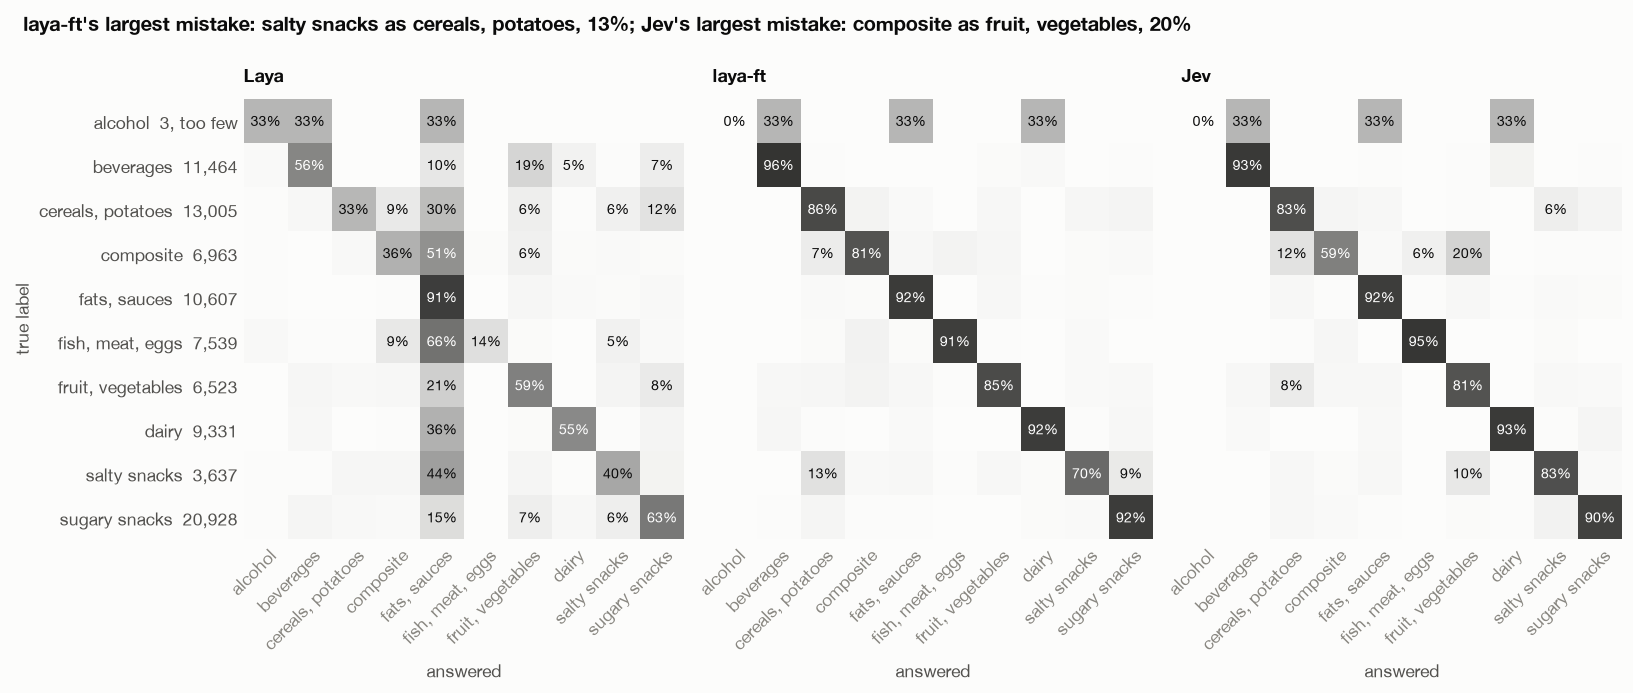

In [15]:
fig = confusion_chart("food_group", SHORT, (13.5, 5.6))
mistakes = {system: worst_mistake(system, "food_group") for system in ("laya-ft", "jev")}
headline(fig, "; ".join(
    f"{NAMES[system]}'s largest mistake: {SHORT[label]} as {SHORT[answer]}, {share:.0%}"
    for system, (label, answer, share) in mistakes.items()
))
plt.show()

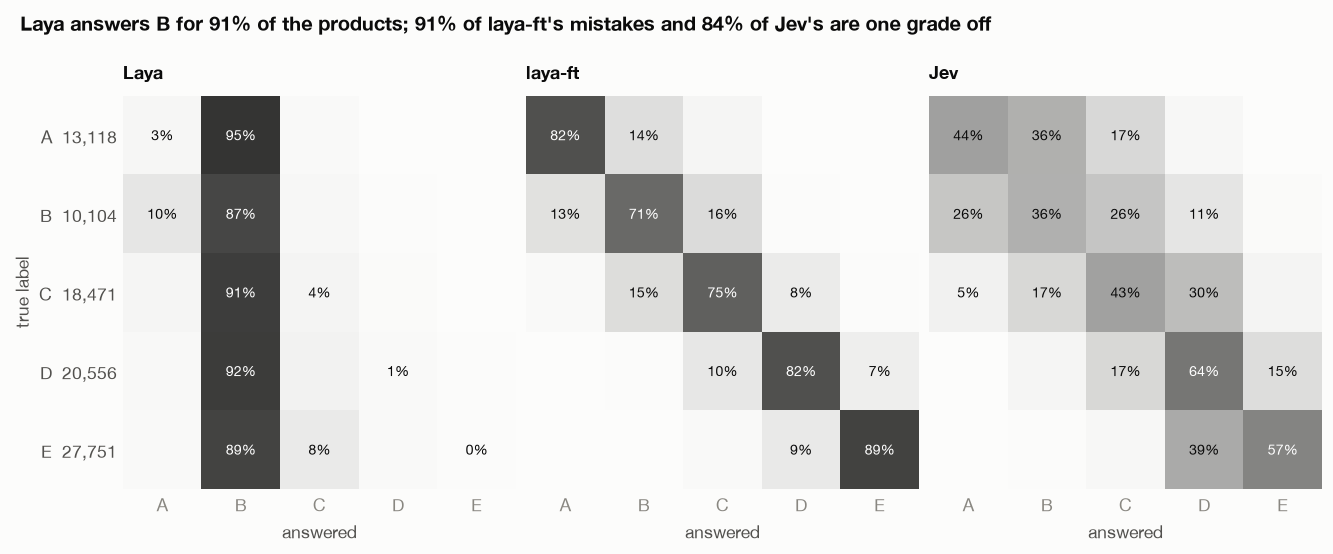

In [16]:
fig = confusion_chart("nutriscore", {grade: grade for grade in GRADES}, (11, 4.5), rotate=False)
favourite = nutriscore[nutriscore.system == "laya"].answer.value_counts(normalize=True)
one_off = {}
for system in ("laya-ft", "jev"):
    wrong = nutriscore[(nutriscore.system == system) & ~nutriscore.right]
    one_off[system] = ((wrong.answer.map(GRADES.index) - wrong.truth.map(GRADES.index)).abs() == 1).mean()
headline(fig, f"Laya answers {favourite.index[0]} for {favourite.iloc[0]:.0%} of the products; "
              f"{one_off['laya-ft']:.0%} of laya-ft's mistakes and {one_off['jev']:.0%} of Jev's are one grade off")
plt.show()

## 5. Agreement

How often two systems give the same answer, whether right or wrong:

In [17]:
answer_of = evaluation.set_index(["question", "id", "system"]).answer.unstack("system")
right_of = evaluation.set_index(["question", "id", "system"]).right.unstack("system")
PAIRS = [("laya-ft", "jev"), ("laya", "jev"), ("laya", "laya-ft")]

show(pd.DataFrame([
    {"question": question, **{f"{NAMES[a]} and {NAMES[b]}": pct((answer_of.loc[question][a] == answer_of.loc[question][b]).mean())
                              for a, b in PAIRS}}
    for question in QUESTIONS
]))

question,laya-ft and Jev,Laya and Jev,Laya and laya-ft
food_group,86.1%,55.1%,54.0%
ultra_processed,90.3%,61.2%,62.6%
nutriscore,53.0%,15.7%,13.3%


And who is right when `laya-ft` and Jev are compared product by product:

In [18]:
rows = []
for question in QUESTIONS:
    ft, jev = right_of.loc[question]["laya-ft"], right_of.loc[question]["jev"]
    rows.append({
        "question": question,
        "both right": pct((ft & jev).mean()),
        "only laya-ft right": pct((ft & ~jev).mean()),
        "only Jev right": pct((~ft & jev).mean()),
        "both wrong": pct((~ft & ~jev).mean()),
    })
show(pd.DataFrame(rows))

question,both right,only laya-ft right,only Jev right,both wrong
food_group,81.8%,7.5%,5.2%,5.6%
ultra_processed,88.8%,8.8%,1.0%,1.4%
nutriscore,45.3%,36.2%,6.5%,12.0%


Ten products, drawn at random, where `laya-ft` and Jev give a different food group:

In [19]:
food = (evaluation[evaluation.question == "food_group"].set_index(["id", "system"])[["answer", "confidence"]]
        .unstack("system"))
differ = food[food.answer["laya-ft"] != food.answer["jev"]]
picked = differ.sample(10, random_state=0).sort_index()

show(pd.DataFrame({
    "id": picked.index,
    "product": picked.index.map(name_of),
    "label": [truth[id]["food_group"] for id in picked.index],
    "laya-ft": [f"{answer} {p:.2f}" for answer, p in zip(picked.answer["laya-ft"], picked.confidence["laya-ft"])],
    "Jev": [f"{answer} {p:.2f}" for answer, p in zip(picked.answer["jev"], picked.confidence["jev"])],
}))
print(f"{len(differ):,} of {len(food):,} food groups differ, {pct(len(differ) / len(food))}")

id,product,label,laya-ft,Jev
"32,170",Spicy all dressed,salty snacks,cereals and potatoes 0.60,salty snacks 1.00
"39,245",Organic Hummus,fats and sauces,fats and sauces 0.97,cereals and potatoes 0.63
"48,375",Pringles BBQ,cereals and potatoes,cereals and potatoes 0.95,salty snacks 1.00
"53,954",Condensed Light Tomato Soup,fruits and vegetables,composite foods 0.81,fruits and vegetables 1.00
"54,805",Organic pinto beans,cereals and potatoes,fruits and vegetables 0.52,cereals and potatoes 0.99
"67,771",Habas Lima Beans,cereals and potatoes,fruits and vegetables 0.78,cereals and potatoes 0.88
"76,392",Heart Healthy Mix,salty snacks,fruits and vegetables 0.81,salty snacks 0.97
"78,470",Pink lemonade,fruits and vegetables,fruits and vegetables 0.58,beverages 1.00
"79,519",Green curry soup,composite foods,composite foods 0.95,fruits and vegetables 0.83
"83,501","Macaroni & Cheese, Real Aged Cheddar",composite foods,cereals and potatoes 0.45,composite foods 0.66


12,555 of 90,000 food groups differ, 14.0%


Read one by one, Jev is right on six of the ten and `laya-ft` on four:

- **Beans**: twice `laya-ft` answers fruits and vegetables where Open Food Facts files beans, as legumes, under cereals and potatoes; Jev follows the taxonomy.
- **Doubtful labels**: two of the four that `laya-ft` gets right have a debatable label: Pringles under cereals and potatoes, a pink lemonade under fruits and vegetables.
  `laya-ft` agrees with them, probably because it was trained on labels like them; Jev answers what a person would, at a confidence of 1.00.
- **Soups** go both ways: the tomato soup is labelled fruits and vegetables, the green curry soup composite foods, and each system gets one of them.
- **Confidence**: `laya-ft` is unsure on half of its wrong answers here, at 0.45 to 0.60, while Jev's wrong answers come at 0.63 to 1.00.

## 6. Confidence

Every answer comes with a probability.
A system is calibrated when the answers it gives with 80% confidence are right 80% of the time; only then can its confidence decide which answers to keep.

- **Laya** ships over-confident, so its temperature is fitted here on the 10,000 calibration products, per question, with Laya's own fitter, `laya.calibrate.fit_temperature_map`.
  The fitter takes scores: the logarithms of the served probabilities are the scores up to a constant per answer, so the fitted temperature applies on top of the one Laya ships with.
- **`laya-ft`** had its temperatures fitted during training, on 1,500 calibration items it did not train on, and its server applies them: it is measured as served.
- **Jev** is measured as it comes; there is nothing to fit.

In [20]:
FLOOR = 5e-5  # Laya serves 4 decimals, so a 0.0000 is anything below half of the last one


def matrix(answers: pd.DataFrame, question: str) -> np.ndarray:
    """The probability of every option, one row per answer, in the order of OPTIONS."""
    return np.array([[probs[option] for option in OPTIONS[question]] for probs in answers.probs])


def label_index(answers: pd.DataFrame, question: str) -> np.ndarray:
    return np.array([OPTIONS[question].index(label) for label in answers.truth])


def bucket(question: str) -> str:
    """The key Laya stores a question's temperature under: its type and number of options."""
    return temp_bucket(QTYPES[QUESTIONS[question]["type"]], len(OPTIONS[question]))


def with_temperature(probs: np.ndarray, temperature: float) -> np.ndarray:
    scores = np.log(np.clip(probs, FLOOR, None)) / temperature
    weights = np.exp(scores - scores.max(axis=1, keepdims=True))
    return weights / weights.sum(axis=1, keepdims=True)


laya = results[results.system == "laya"]
records = []
for question in QUESTIONS:
    answers = laya[(laya.split == "calibration") & (laya.question == question)]
    targets = np.eye(len(OPTIONS[question]))[label_index(answers, question)]
    qtype, options = QTYPES[QUESTIONS[question]["type"]], len(OPTIONS[question])
    records += [(qtype, np.log(np.clip(probs, FLOOR, None)), target, options)
                for probs, target in zip(matrix(answers, question), targets)]
fit = fit_temperature_map(records)
temperature = {question: fit["temperature_by_options"][bucket(question)] for question in QUESTIONS}

show(pd.DataFrame([
    {
        "question": question,
        "Laya's bucket": bucket(question),
        "calibration answers": fit["n_by_bucket"][bucket(question)],
        "fitted temperature": f"{temperature[question]:.2f}",
        "where the fit wanted to go": (f"{fit['temperature_clamped'][bucket(question)]['fitted']:,.0f}, "
                                       f"past Laya's limit of {temperature[question]:.0f}"
                                       if bucket(question) in fit["temperature_clamped"] else ""),
    }
    for question in QUESTIONS
]))

question,Laya's bucket,calibration answers,fitted temperature,where the fit wanted to go
food_group,choice:6-10,"10,000",0.98,
ultra_processed,noul:2,"10,000",1.80,
nutriscore,score:3-5,"10,000",5.00,"2,552, past Laya's limit of 5"


A temperature above 1 softens Laya's probabilities, one below 1 sharpens them; neither changes an answer.
On `nutriscore` the fit runs off to an unlimited temperature, where every grade gets the same 20%.
Its probabilities carry no usable information about the grade, so the best that calibration can do is to say "no idea"; Laya stops it at 5.

In [21]:
VARIANTS = {"Laya as shipped": "laya", "Laya, fitted": "laya", "laya-ft": "laya-ft", "Jev": "jev"}
STYLE = {"Laya as shipped": (0, (2, 1.6)), "Laya, fitted": "-", "laya-ft": "-", "Jev": "-"}

scored = {}
for question in QUESTIONS:
    for variant, system in VARIANTS.items():
        answers = evaluation[(evaluation.system == system) & (evaluation.question == question)]
        probs = matrix(answers, question)
        if variant == "Laya, fitted":
            probs = with_temperature(probs, temperature[question])
        scored[variant, question] = probs, label_index(answers, question)


def calibration(probs: np.ndarray, labels: np.ndarray) -> dict:
    confidence, right = probs.max(axis=1), (probs.argmax(axis=1) == labels).astype(float)
    return {
        "accuracy": right.mean(),
        "mean confidence": confidence.mean(),
        "ECE": ece_score(confidence, right),  # Laya's own, with 15 bins, as in the training report
        "Brier": ((probs - np.eye(probs.shape[1])[labels]) ** 2).sum(axis=1).mean(),
    }


metrics = {key: calibration(*value) for key, value in scored.items()}
show(pd.DataFrame([
    {"question": question, "system": variant, **{name: f"{value:.3f}" for name, value in metrics[variant, question].items()}}
    for question in QUESTIONS for variant in VARIANTS
]))

question,system,accuracy,mean confidence,ECE,Brier
food_group,Laya as shipped,0.529,0.511,0.031,0.622
food_group,"Laya, fitted",0.529,0.518,0.025,0.621
food_group,laya-ft,0.892,0.887,0.023,0.164
food_group,Jev,0.869,0.946,0.077,0.215
ultra_processed,Laya as shipped,0.626,0.727,0.101,0.469
ultra_processed,"Laya, fitted",0.626,0.643,0.030,0.447
ultra_processed,laya-ft,0.976,0.969,0.008,0.038
ultra_processed,Jev,0.898,0.833,0.066,0.155
nutriscore,Laya as shipped,0.114,0.534,0.420,1.091
nutriscore,"Laya, fitted",0.114,0.275,0.161,0.842


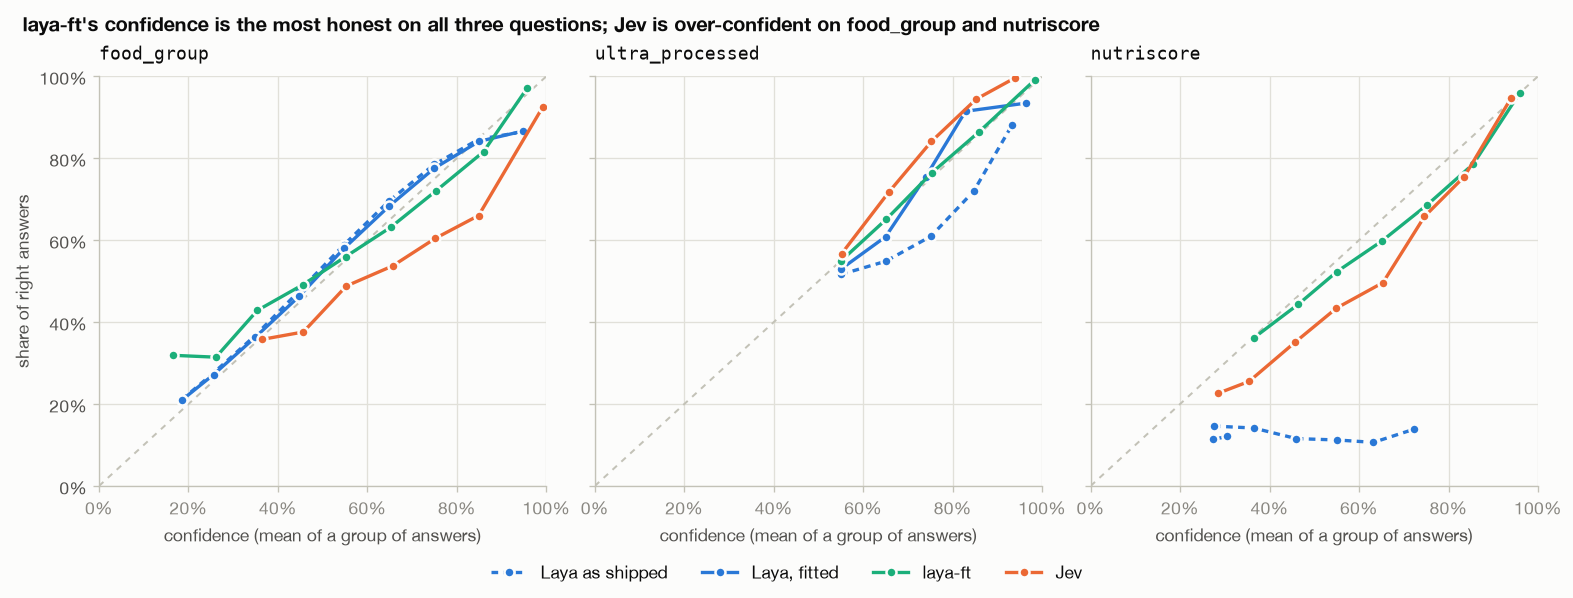

In [22]:
EDGES = np.linspace(0, 1, 11)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.9), layout="constrained", sharey=True)
for ax, question in zip(axes, QUESTIONS):
    ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1.2, linestyle=(0, (3, 3)))
    for variant, system in VARIANTS.items():
        probs, labels = scored[variant, question]
        confidence = probs.max(axis=1)
        groups = pd.DataFrame({
            "bin": np.digitize(confidence, EDGES[1:-1]),
            "confidence": confidence,
            "right": probs.argmax(axis=1) == labels,
        }).groupby("bin").agg(products=("right", "size"), confidence=("confidence", "mean"), right=("right", "mean"))
        groups = groups[groups.products >= 100]  # a point on fewer products is noise
        ax.plot(groups.confidence, groups.right, color=COLOR[system], linestyle=STYLE[variant], linewidth=2,
                marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5, label=variant)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    percent_axis(ax, "x")
    percent_axis(ax, "y")
    ax.set_title(question, fontfamily="monospace", color=INK)
    ax.set_xlabel("confidence (mean of a group of answers)")
axes[0].set_ylabel("share of right answers")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="outside lower center", ncols=4)

honest = [question for question in QUESTIONS
          if min(VARIANTS, key=lambda variant: metrics[variant, question]["ECE"]) == "laya-ft"]
over = [question for question in QUESTIONS
        if metrics["Jev", question]["mean confidence"] > metrics["Jev", question]["accuracy"] + 0.02]
headline(fig, f"laya-ft's confidence is the most honest on {COUNT[len(honest)]} questions; "
              f"Jev is over-confident on {' and '.join(over) or 'none'}")
plt.show()

In [23]:
lines = []
for question in QUESTIONS:
    shipped, fitted = metrics["Laya as shipped", question], metrics["Laya, fitted", question]
    jev = metrics["Jev", question]
    lines.append(
        f"- `{question}`: fitting moves Laya's calibration error (ECE) from {shipped['ECE']:.3f} to {fitted['ECE']:.3f}. "
        f"`laya-ft` is at {metrics['laya-ft', question]['ECE']:.3f}; "
        f"Jev at {jev['ECE']:.3f}, {pct(jev['mean confidence'], 0)} sure on average and right {pct(jev['accuracy'], 0)} of the time."
    )
display(Markdown("\n".join(lines)))

- `food_group`: fitting moves Laya's calibration error (ECE) from 0.031 to 0.025. `laya-ft` is at 0.023; Jev at 0.077, 95% sure on average and right 87% of the time.
- `ultra_processed`: fitting moves Laya's calibration error (ECE) from 0.101 to 0.030. `laya-ft` is at 0.008; Jev at 0.066, 83% sure on average and right 90% of the time.
- `nutriscore`: fitting moves Laya's calibration error (ECE) from 0.420 to 0.161. `laya-ft` is at 0.033; Jev at 0.111, 63% sure on average and right 52% of the time.

## 7. Accuracy against coverage

A decision model does not have to answer every product.
Keep the answers it is surest about, and send the rest to a person or to another system: the share kept is the coverage, and the accuracy on that share is what the pipeline gets.
Laya is ordered by its fitted confidence; the temperature can change the order of two products, never their answers.
The lines start at 1% of the products, 900 of them: on fewer, the accuracy is noise.

In [24]:
MIN_COVERAGE = 0.01


def coverage_curve(probs: np.ndarray, labels: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """The share of products kept and the accuracy on them, keeping the surest first."""
    confidence = probs.max(axis=1)
    order = np.argsort(-confidence, kind="stable")
    right = (probs.argmax(axis=1) == labels)[order]
    kept = np.arange(1, len(order) + 1)
    # Products with the same confidence are kept or left together: only the last of a tie is a point
    last = np.r_[confidence[order][1:] != confidence[order][:-1], True]
    coverage, accuracy = kept[last] / len(order), (np.cumsum(right) / kept)[last]
    return coverage[coverage >= MIN_COVERAGE], accuracy[coverage >= MIN_COVERAGE]


def accuracy_at(curve: tuple[np.ndarray, np.ndarray], share: float) -> float:
    coverage, accuracy = curve
    return accuracy[np.searchsorted(coverage, share)]  # the first point that keeps at least `share`


CURVES = {"Laya, fitted": "laya", "laya-ft": "laya-ft", "Jev": "jev"}
curves = {(variant, question): coverage_curve(*scored[variant, question]) for variant in CURVES for question in QUESTIONS}

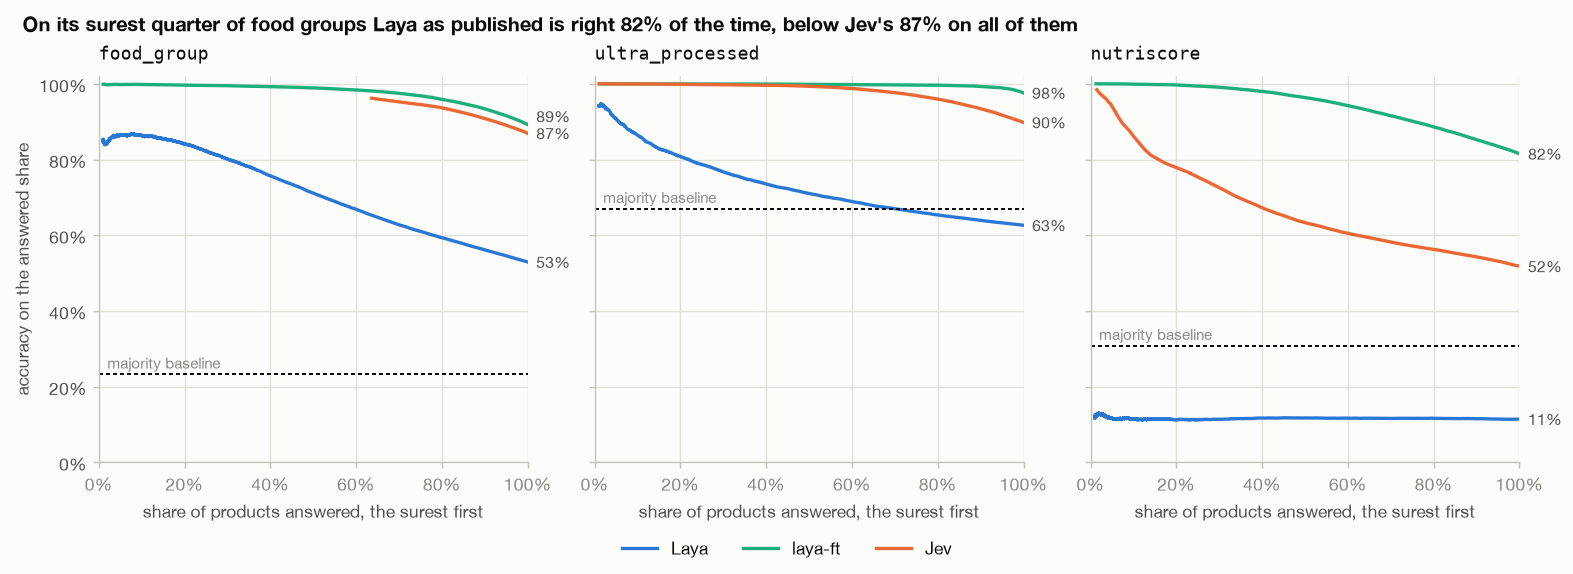

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.7), layout="constrained", sharey=True)
for ax, question in zip(axes, QUESTIONS):
    ends = []
    for variant, system in CURVES.items():
        coverage, right = curves[variant, question]
        ax.plot(coverage, right, color=COLOR[system], linewidth=2, label=NAMES[system])
        ends.append([right[-1], system])
    ax.axhline(baseline[question], color=INK, linewidth=1.2, linestyle=(0, (2, 1.5)))
    ax.text(0.02, baseline[question] + 0.015, "majority baseline", color=MUTED, fontsize=9)
    # The overall accuracy at the end of each line, nudged apart where two are close
    ends.sort()
    for i in range(1, len(ends)):
        ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.045)
    for y, system in ends:
        ax.text(1.02, y, pct(accuracy.loc[question, system], 0), va="center", color=INK_2, fontsize=9.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    percent_axis(ax, "x")
    percent_axis(ax, "y")
    ax.set_title(question, fontfamily="monospace", color=INK)
    ax.set_xlabel("share of products answered, the surest first")
axes[0].set_ylabel("accuracy on the answered share")
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="outside lower center", ncols=3)

quarter = accuracy_at(curves["Laya, fitted", "food_group"], 0.25)
jev_all = accuracy.loc["food_group", "jev"]
headline(fig, f"On its surest quarter of food groups Laya as published is right {quarter:.0%} of the time, "
              f"{'below' if quarter < jev_all else 'above'} Jev's {jev_all:.0%} on all of them")
FIGURES.mkdir(exist_ok=True)
fig.savefig(FIGURES / "accuracy-against-coverage.png", dpi=150)
plt.show()

In [26]:
SHARES = [0.1, 0.25, 0.5, 0.75, 1.0]
show(pd.DataFrame([
    {"question": question, "system": NAMES[system],
     **{f"surest {share:.0%}": pct(accuracy_at(curves[variant, question], share)) for share in SHARES}}
    for question in QUESTIONS for variant, system in CURVES.items()
]))

question,system,surest 10%,surest 25%,surest 50%,surest 75%,surest 100%
food_group,Laya,86.3%,82.2%,71.1%,61.0%,52.9%
food_group,laya-ft,99.9%,99.6%,98.9%,96.8%,89.2%
food_group,Jev,96.2%,96.2%,96.2%,94.5%,86.9%
ultra_processed,Laya,86.4%,78.7%,71.0%,66.2%,62.6%
ultra_processed,laya-ft,100.0%,100.0%,99.9%,99.7%,97.6%
ultra_processed,Jev,100.0%,99.8%,99.3%,96.7%,89.8%
nutriscore,Laya,11.4%,11.3%,11.7%,11.6%,11.4%
nutriscore,laya-ft,99.9%,99.4%,96.4%,90.1%,81.5%
nutriscore,Jev,86.0%,74.4%,63.1%,57.1%,51.8%


In [27]:
certain = {question: (scored["Jev", question][0].max(axis=1) == 1).mean() for question in QUESTIONS}
display(Markdown("\n".join(
    f"- Jev's `{question}` line starts at {pct(certain[question], 0)}: it gives that share of its answers a confidence "
    "of exactly 1.00, and answers with the same confidence are kept or left together."
    for question in QUESTIONS if certain[question] >= MIN_COVERAGE
)))

- Jev's `food_group` line starts at 64%: it gives that share of its answers a confidence of exactly 1.00, and answers with the same confidence are kept or left together.

## 8. Speed and cost

Laya's speed on the laptop comes from the first look, on its 1,024 products; the full runs went to the DGX Spark to finish in time.
Jev's rate is the harness's own cap of 600 requests a minute, half the published limit, not Jev's speed.

In [28]:
JEV_USD_PER_MILLION_TOKENS = 0.042  # input tokens; output tokens are free (vendor figure, see the README)
USD_PER_EUR = 1.1172  # the ECB reference rate of 30 October 2026


def products_per_second(run: str, system: str) -> float:
    invocations = [i for i in json.loads((RUNS / run / f"{system}.json").read_text())["invocations"] if i["sent"]]
    return sum(i["sent"] for i in invocations) / sum(i["seconds"] for i in invocations)


jev = evaluation[evaluation.system == "jev"].drop_duplicates("id")
tokens = jev.input_tokens.mean()
usd_per_million = tokens * JEV_USD_PER_MILLION_TOKENS  # a million products of `tokens` each, at a price per million tokens

speeds = [
    ("Laya", "M3 Pro laptop", products_per_second("first-look", "laya"), "own hardware"),
    ("Laya", "DGX Spark", products_per_second("full", "laya"), "own hardware"),
    ("laya-ft", "DGX Spark", products_per_second("full", "laya-ft"), "own hardware"),
    ("Jev", "TypeSafe's API", products_per_second("full", "jev"),
     f"€{usd_per_million / USD_PER_EUR:.2f} (${usd_per_million:.2f})"),
]
show(pd.DataFrame([
    {"system": system, "answered on": where, "products per second": f"{rate:.1f}",
     "hours per million products": f"{1e6 / rate / 3600:.0f}", "cost per million products": cost}
    for system, where, rate, cost in speeds
]))
print(f"Jev: {tokens:.0f} input tokens per product on average, median {jev.input_tokens.median():.0f}; "
      f"latency per request p50 {jev.latency_ms.median():.0f} ms, p95 {jev.latency_ms.quantile(0.95):.0f} ms")

system,answered on,products per second,hours per million products,cost per million products
Laya,M3 Pro laptop,5.0,56,own hardware
Laya,DGX Spark,25.2,11,own hardware
laya-ft,DGX Spark,25.1,11,own hardware
Jev,TypeSafe's API,9.7,29,€33.38 ($37.29)


Jev: 888 input tokens per product on average, median 867; latency per request p50 162 ms, p95 238 ms


## 9. In short

In [29]:
lead = {question: accuracy.loc[question, "laya-ft"] - accuracy.loc[question, "jev"] for question in QUESTIONS}
ahead = [question for question in QUESTIONS if lead[question] > 0]
coverage_line = (f"Answering only its surest quarter of food groups, Laya as published is right {quarter:.0%} of the time, "
                 f"{'below' if quarter < jev_all else 'above'} Jev's {jev_all:.0%} on all of them.")
display(Markdown("\n".join([
    "- Accuracy on the 90,000 evaluation products, `food_group`, `ultra_processed`, `nutriscore`: " + "; ".join(
        f"{NAMES[system]} {', '.join(pct(accuracy.loc[question, system]) for question in QUESTIONS)}" for system in SYSTEMS
    ) + ".",
    (f"- `laya-ft`, Laya fine-tuned on the 10,000 calibration products, is ahead of Jev on {COUNT[len(ahead)]} questions "
     f"({', '.join(f'{lead[question] * 100:+.1f} points on `{question}`' for question in QUESTIONS)}), "
     f"and on {COUNT[len(ahead_unseen)]} for the products whose name it never saw."),
    (f"- Laya as published is below the majority baseline on {COUNT[len(below)]} questions; "
     f"on `nutriscore` it answers {favourite.index[0]} for {favourite.iloc[0]:.0%} of the products."),
    "- " + coverage_line,
    (f"- `laya-ft`'s confidence is the most honest on {COUNT[len(honest)]} questions; "
     f"Jev is over-confident on {' and '.join(f'`{q}`' for q in over) or 'none'}."),
    (f"- Laya answers {products_per_second('first-look', 'laya'):.1f} products a second on the M3 Pro laptop and "
     f"{products_per_second('full', 'laya'):.1f} on the DGX Spark; Jev costs €{usd_per_million / USD_PER_EUR:.0f} "
     "per million products in input tokens."),
])))

- Accuracy on the 90,000 evaluation products, `food_group`, `ultra_processed`, `nutriscore`: Laya 52.9%, 62.6%, 11.4%; laya-ft 89.2%, 97.6%, 81.5%; Jev 86.9%, 89.8%, 51.8%.
- `laya-ft`, Laya fine-tuned on the 10,000 calibration products, is ahead of Jev on all three questions (+2.3 points on `food_group`, +7.8 points on `ultra_processed`, +29.7 points on `nutriscore`), and on all three for the products whose name it never saw.
- Laya as published is below the majority baseline on two questions; on `nutriscore` it answers B for 91% of the products.
- Answering only its surest quarter of food groups, Laya as published is right 82% of the time, below Jev's 87% on all of them.
- `laya-ft`'s confidence is the most honest on all three questions; Jev is over-confident on `food_group` and `nutriscore`.
- Laya answers 5.0 products a second on the M3 Pro laptop and 25.2 on the DGX Spark; Jev costs €33 per million products in input tokens.